In [ ]:
# !pip install -U imbalßanced-learn

## **언더 샘플링(Under Sampling)**

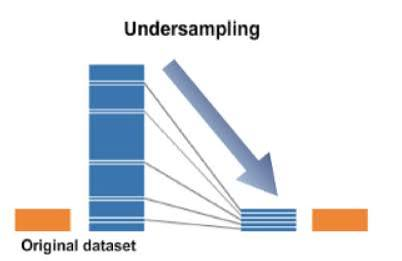

- **다수의 레이블**을 가진 데이터를 샘플링하여,<br>
**소수의 데이터 세트가 가진 레이블의 수 수준**으로 감소시키는 기법이다.</br>

- 이 기법을 사용하면 데이터 불균형으로 인한 문제는 피할 수 있지만,<br>
전체 데이터의 수가 급격하게 줄어들어 학습성능을 떨어뜨리는 결과를 초래할 수 있다.</br>

In [ ]:
# 다양한 샘플링 함수를 제공하는 imblearn 모듈을 사용한다.
# 우선 모듈을 설치하고 95:1의 불균형 데이터를 만들어본다.
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
from collections import Counter
from imblearn.under_sampling import RandomUnderSampler

x, y = make_classification(n_samples=2000, n_features=6,
                           weights=[0.95], flip_y=0)
print(Counter(y))

Counter({np.int64(0): 1900, np.int64(1): 100})


In [8]:
'''
Random Under Samplig(랜덤 언더 샘플링):
다수를 차지하는 레이블에서 무작위로 데이터를 제거하는 방법이다.
'''

# sampling_strategy 파라미터를 majority로 지정하면 
# 다수 레이블의 데이터를 샘플링하여 소수 레이블의 데이터의 수와 동일하게 줄인다.
undersample = RandomUnderSampler(sampling_strategy='majority')
x_under, y_under = undersample.fit_resample(x,y)

print(Counter(y_under))

# sampling_strategy 파라미터를 0~1 사이의 숫자값으로 지정하면
# 소수 레이블, 다수 레이블의 데이터 수가 해당 비율이 되도록 조정한다, 
undersample = RandomUnderSampler(sampling_strategy=0.5)
x_under2, y_under2 = undersample.fit_resample(x, y)

print(Counter(y_under2))

Counter({np.int64(0): 100, np.int64(1): 100})
Counter({np.int64(0): 200, np.int64(1): 100})


## **오버 샘플링(Over Sampling)**

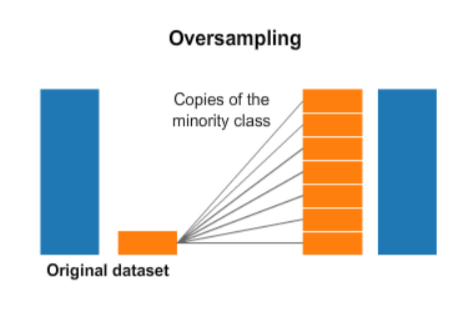

- **소수의 레이블**을 지닌 데이터를 **다수의 레이블을 지닌 데이터 세트의 수**만큼 증식 시켜<br>
**학습에 사용하기 위한 충분한 양과 비율의 데이터를 확보**하는 기법이다.</br>

- 이 기법을 사용하면 **데이터 불균형으로 인한 문제는 피할 수 있지만**,<br>
**전체 데이터의 수가 급격하게 줄어들어 학습성능을 떨어뜨리는 결과**를 초래할 수 있다.</br>

In [9]:
'''
Random Over Samplig(랜덤 오버 샘플링):

- 소수의 레이블을 지닌 데이터세트를 단순 복제하여 다수의 레이블과 비율을 맞추는 방법이다.

- 데이터를 단순 복제하므로 분포는 변하지 않지만, 그 수가 늘어나 같은 비율로 가중치를 받을 수 있다.

- 오버 피팅(과적합)의 위험성이 있지만,
  불균형 문제를 처리하지 않는 것보다는 유효하기 때문에 종종 사용된다.
'''

from imblearn.over_sampling import RandomOverSampler
oversample = RandomOverSampler(sampling_strategy=0.5)
x_over, y_over = oversample.fit_resample(x,y)
print(Counter(y_over))

oversample = RandomOverSampler(sampling_strategy='minority')
x_over, y_over = oversample.fit_resample(x, y)
print(Counter(y_over))



Counter({np.int64(0): 1900, np.int64(1): 950})
Counter({np.int64(0): 1900, np.int64(1): 1900})


## **SMOTE**
## **:(Synthetic Minority Over-sampling Techinque)**

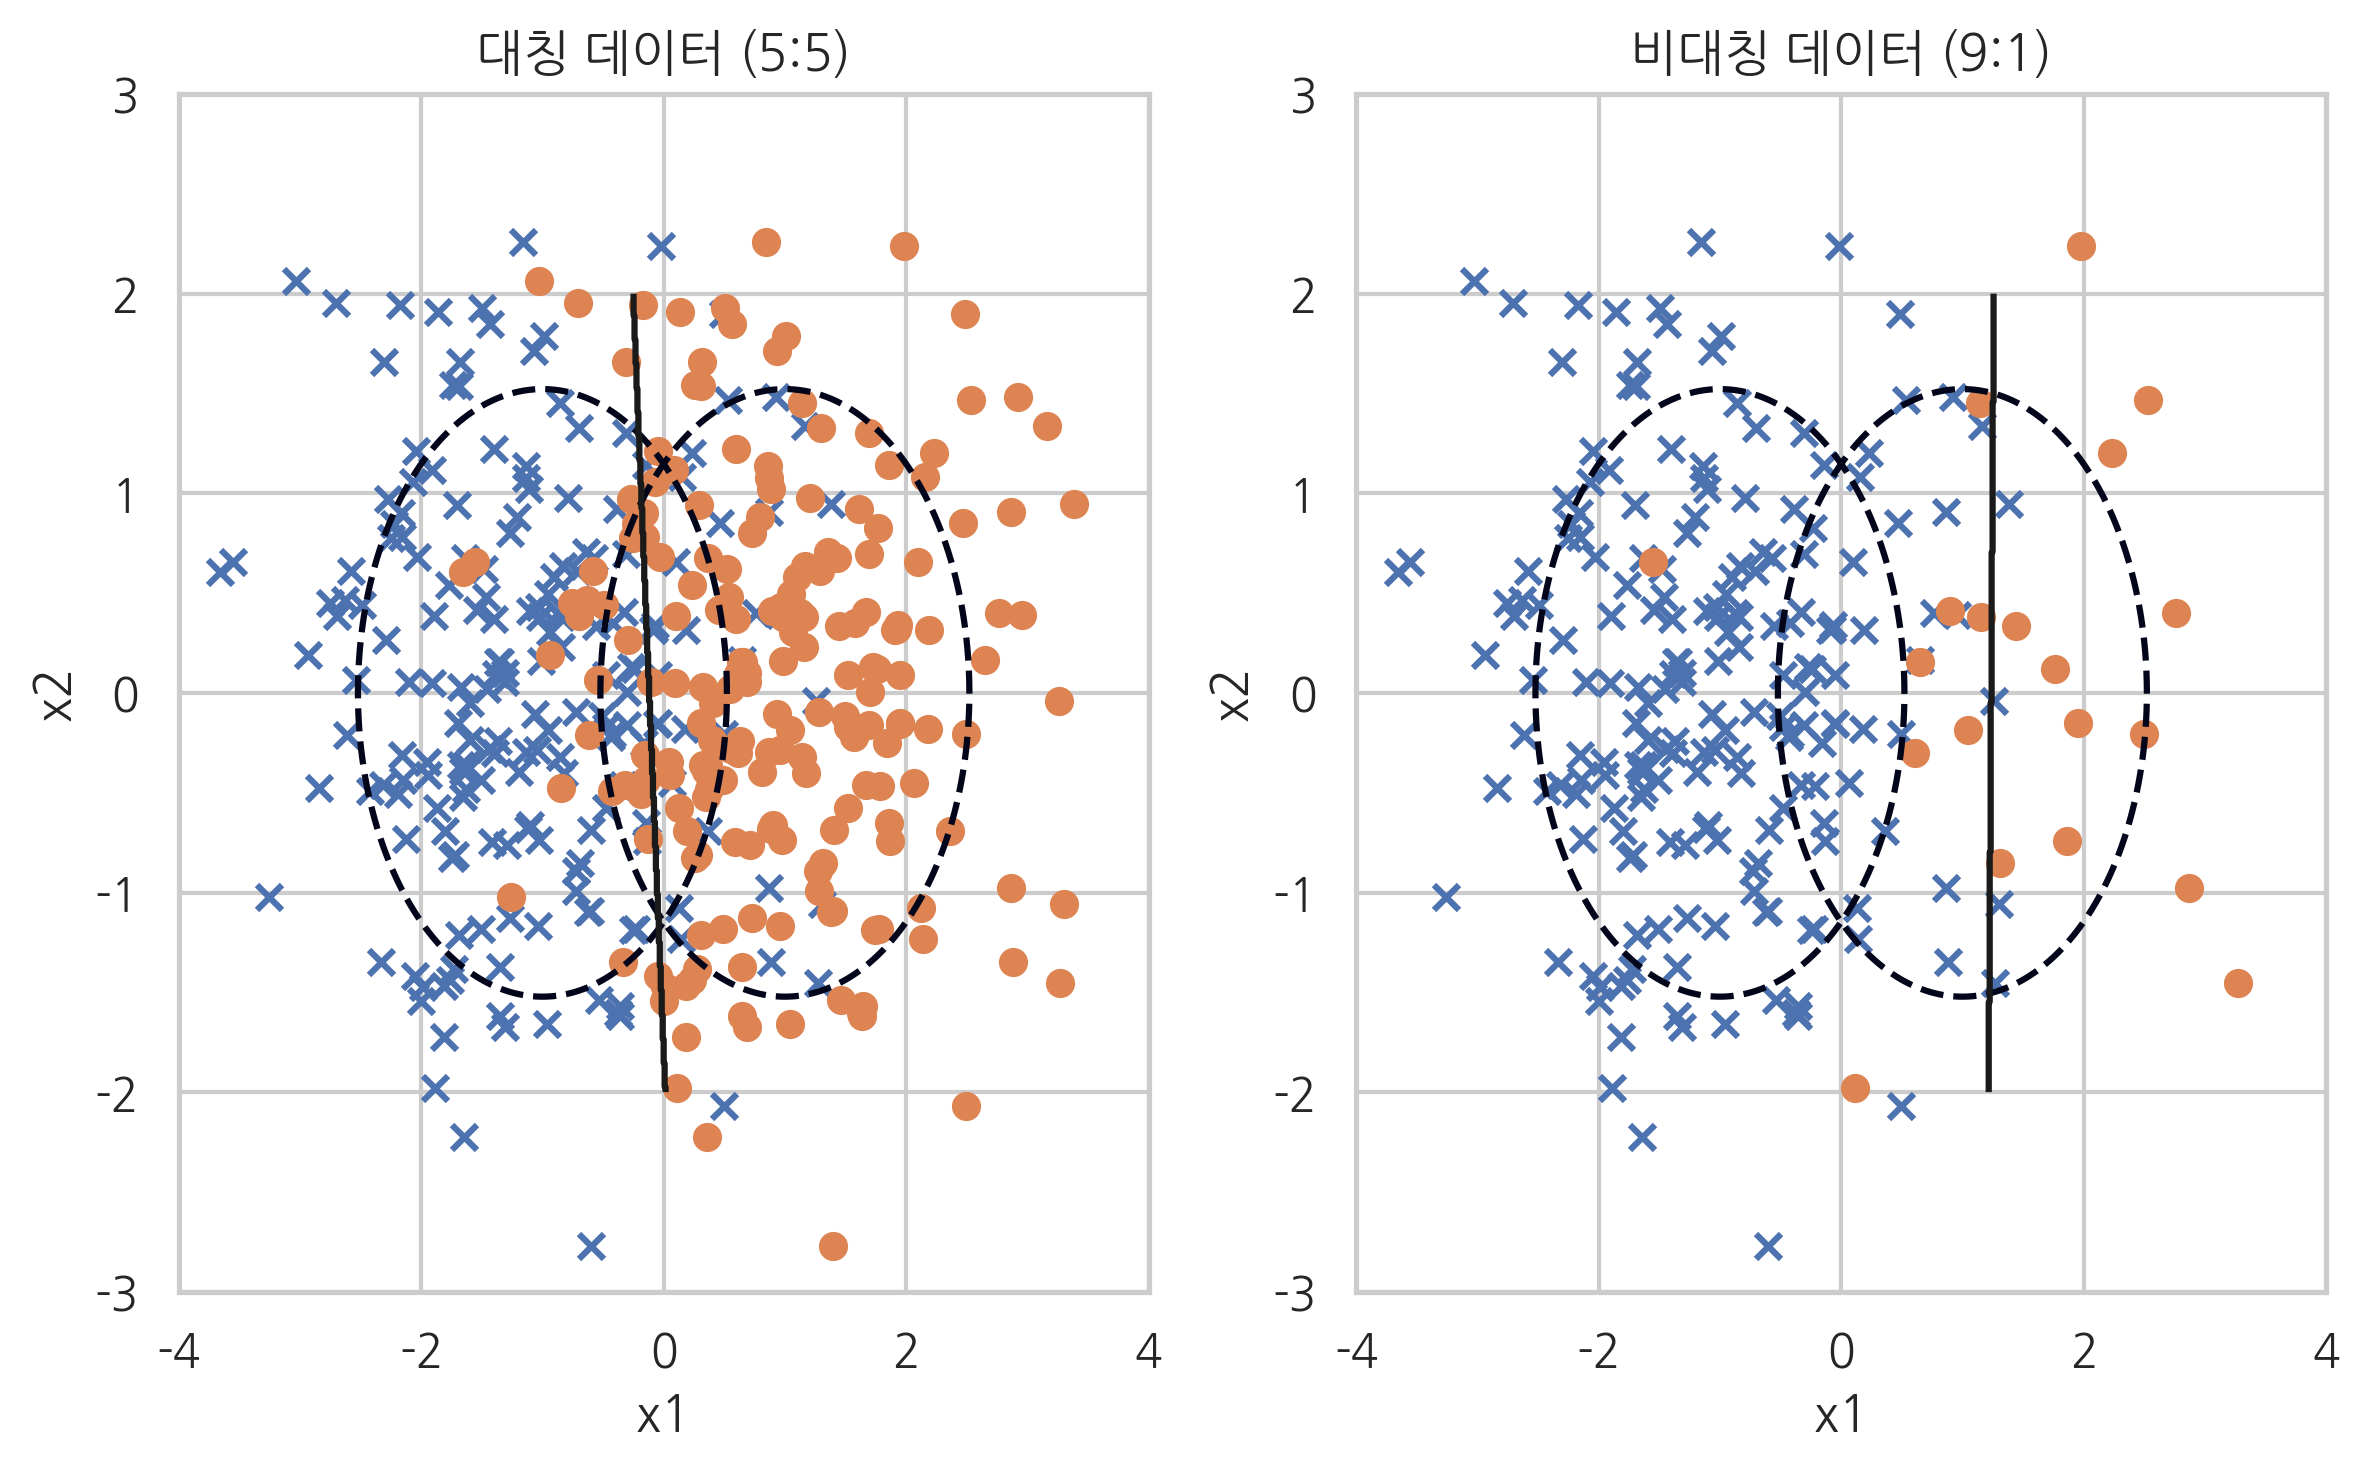

**오버 샘플링 방식**중 하나로,<br>
**소수 레이블을 지닌 데이터세트**의 **관측값**에 대한 **K개의 최근접 이웃**(K-Nearest Neighbor)을 찾고, </br>
**관측 값과 이웃으로 선택된 값** 사이에,
**임의의 새로운 데이터를 생성**하는 방법으로 **샘플의 수를 늘리는 방법**이다.</br>




In [10]:
# SMOTE 코드 예시
from imblearn.over_sampling import SMOTE
smote_sampling = SMOTE(sampling_strategy='minority')
x_sm, y_sm = smote_sampling.fit_resample(x,y)

print(Counter(y_sm))

Counter({np.int64(0): 1900, np.int64(1): 1900})


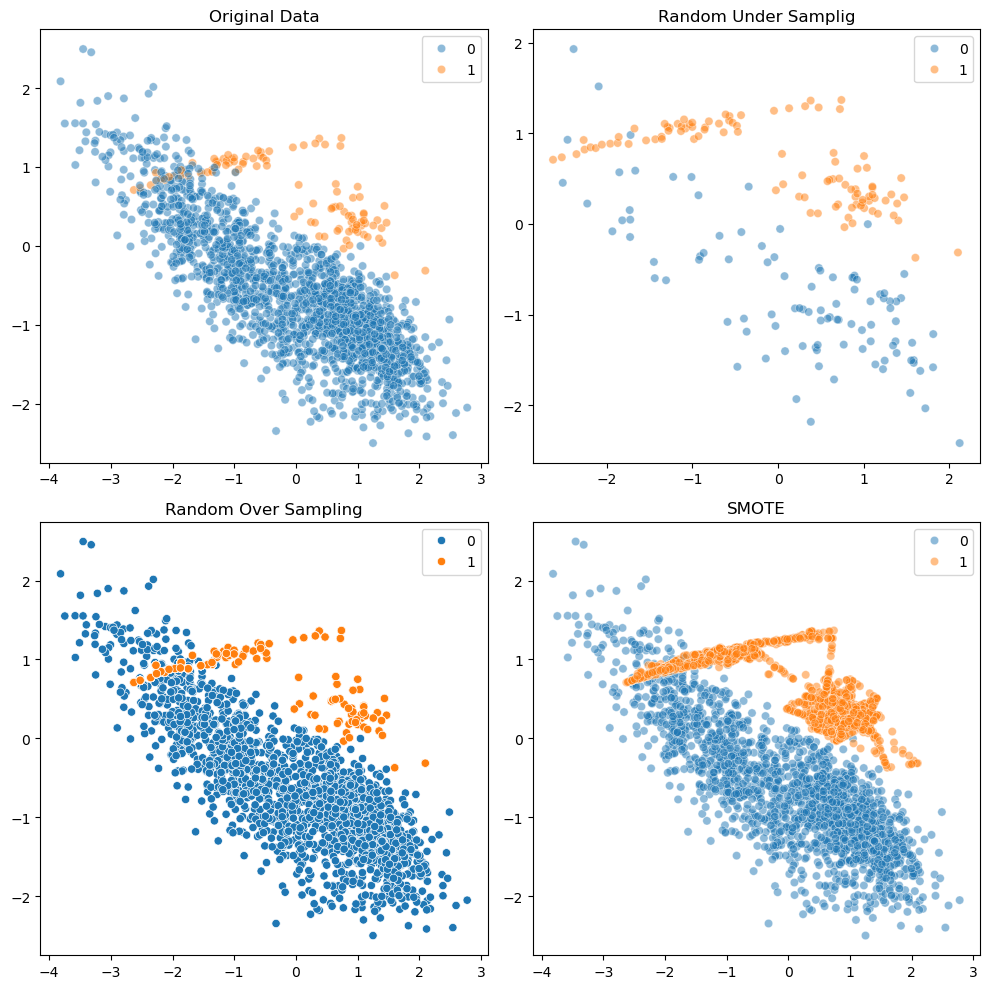

In [ ]:
# 데이터 불균형 기법 적용 결과(시각화)
import matplotlib.pyplot as plt
import seaborn as sns

# 2x2 크기의 subplot 설정
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10,10))

# 원본 데이터 분포 시각화
sns.scatterplot(x=x[:, 1], y=x[:, 2], 
                hue=y, ax=axes[0][0], alpha=0.5)

# 랜덤 언더샘플링 결과 분포 시각화
sns.scatterplot(x=x_under[:, 1], y=x_under[: ,2],
                hue=y_under, ax=axes[0][1], alpha=0.5)

# 랜덤 오버샘플링 결과 분포 시각화
sns.scatterplot(x=x_over[:, 1], y=x_over[:, 2],
                 hue=y_over, ax=axes[1][0])

# SMOTE 결과 분포 시각화
sns.scatterplot(x=x_sm[:, 1], y=x_sm[: ,2],
                hue=y_sm, ax=axes[1][1], alpha=0.5)

# subplot 객체에 할당
axes[0][0].set_title('Original Data')
axes[0][1].set_title('Random Under Samplig')
axes[1][0].set_title('Random Over Sampling')
axes[1][1].set_title('SMOTE')

plt.tight_layout()
plt.show()

위의 **데이터 불균형 조정의 결과**에서,<br>

- **Original Data(원본데이터)** 그래프에서는 0과 1의 레이블 개수가 크게 차이나는 것을 확인할 수 있다.</br>

- **Random Under Sampling**의 결과에서는 <br>
0번 레이블의 개수가 1번 레이블의 개수와 동일한 수준으로 줄어든 것을 확인할 수 있다.</br>

- **Random Over Sampling**은 데이터를 단순 복제하여 <br>
1번 레이블의 관측값들의 위치가 원본 데이터와 차이가 없음을 확인할 수 있다. </br>

- **SMOTE**는 원본 데이터에서 1번 데이터를 새롭게 만들어 내었다.<br>